# ML sobre las features (árbol de decisión → selección → baseline y otros modelos)

Orden del notebook:
1. Carga de `features_train_mini.csv` / `features_val_mini.csv`.
2. **Árbol de decisión** para ver qué features son más útiles (y si esa lista es estable entre folds).
3. Selección de las top-K features. **Se hace dentro de cada fold de la validación cruzada** (no antes),
   para que las métricas no salgan infladas.
4. Baseline (regresión logística) y otros modelos, con **todas** las features y con las **top-K**.
5. Ablación por familias (forma / color / textura).
6. Evaluación final en **val** (solo una vez, sin ajustar nada con ella).

Etiqueta: `label` (nevus = 0, others = 1). Se excluyen `name`, `class`, `subtype` (delata la clase) y `qc_*`.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore")

# ---------------- Configuración ----------------
ROOT = Path(r"C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG")
TRAIN_CSV = ROOT / "processed" / "features_train_mini.csv"
VAL_CSV   = ROOT / "processed" / "features_val_mini.csv"
OUT_DIR   = ROOT / "ml" / "ml_results"          # la carpeta que ya tienes dentro de ml/
K_FEATURES = 30
CV_FOLDS = 5
SEED = 42
N_JOBS = 4
OUT_DIR.mkdir(exist_ok=True)

## 1. Carga de datos

In [2]:
tr, va = pd.read_csv(TRAIN_CSV), pd.read_csv(VAL_CSV)
FEATS = [c for c in tr.columns if c.startswith(("shape_", "color_", "tex_"))]
assert FEATS == [c for c in va.columns if c.startswith(("shape_", "color_", "tex_"))], "train y val tienen columnas distintas"

Xtr, ytr = tr[FEATS].replace([np.inf, -np.inf], np.nan), tr["label"].values
Xva, yva = va[FEATS].replace([np.inf, -np.inf], np.nan), va["label"].values
family = lambda c: c.split("_")[0]

print(f"train: {Xtr.shape}  (others = {ytr.mean():.1%})   val: {Xva.shape}  (others = {yva.mean():.1%})")
print("features por familia:", pd.Series([family(c) for c in FEATS]).value_counts().to_dict())
print("NaN en features: train", int(Xtr.isna().sum().sum()), "| val", int(Xva.isna().sum().sum()))

skf = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)
FAM_COLOR = {"shape": "#1f77b4", "color": "#d62728", "tex": "#2ca02c"}

train: (2000, 197)  (others = 49.1%)   val: (1000, 197)  (others = 49.1%)
features por familia: {'color': 83, 'shape': 76, 'tex': 38}
NaN en features: train 0 | val 0


## 2. Árbol de decisión: ¿qué features son más útiles?

Un árbol poco profundo (`max_depth=5`) es fácil de interpretar. Su importancia de cada feature es la reducción
total de impureza (Gini) que consigue al dividir con ella.
Aviso: **un solo árbol es inestable** (cambia bastante según los datos), por eso también miramos si el ranking
se repite en cada fold.

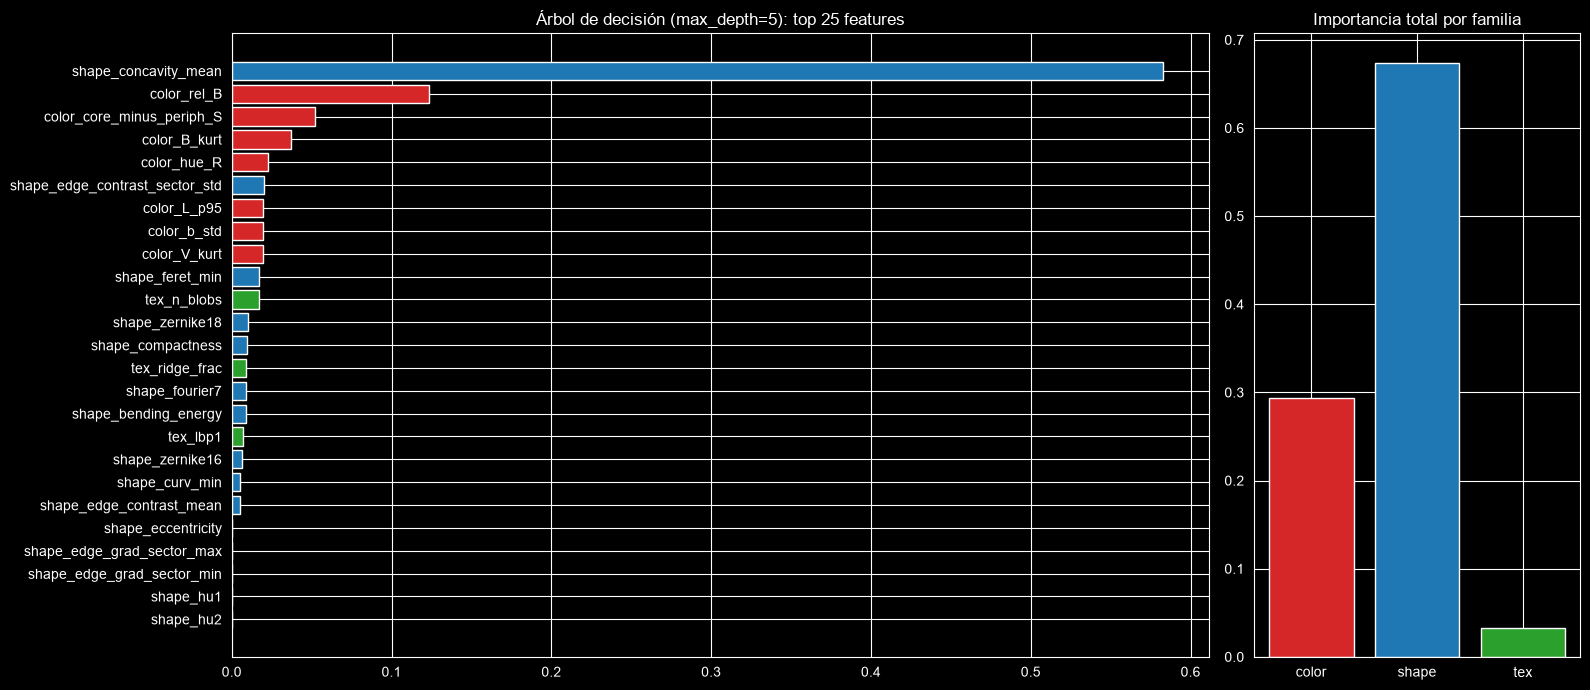

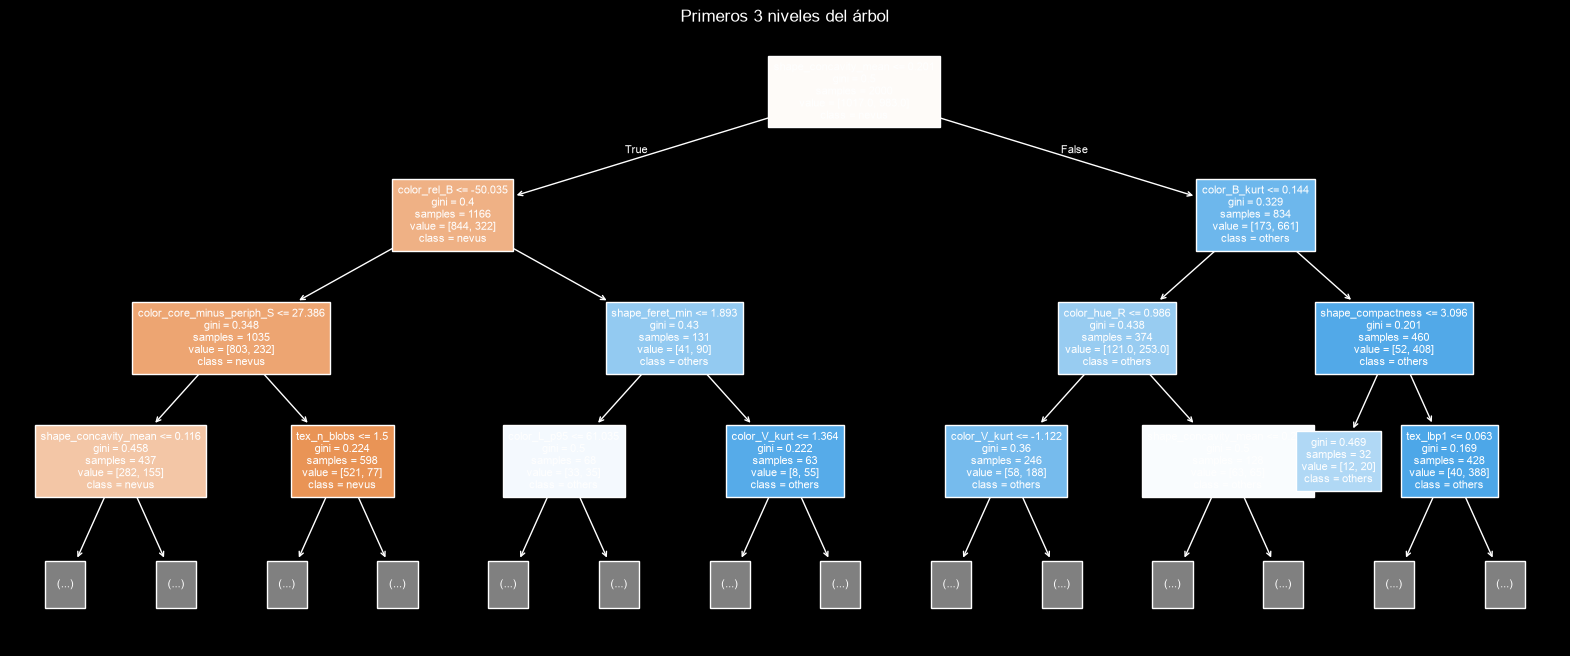

In [3]:
imp = SimpleImputer(strategy="median").fit(Xtr)
Xtr_i = pd.DataFrame(imp.transform(Xtr), columns=FEATS)

tree = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED).fit(Xtr_i, ytr)
imp_tree = pd.Series(tree.feature_importances_, index=FEATS).sort_values(ascending=False)

fig, axs = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [3, 1]})
top = imp_tree.head(25)[::-1]
axs[0].barh(top.index, top.values, color=[FAM_COLOR[family(c)] for c in top.index])
axs[0].set_title("Árbol de decisión (max_depth=5): top 25 features")
fam_imp = imp_tree.groupby(lambda c: family(c)).sum()
axs[1].bar(fam_imp.index, fam_imp.values, color=[FAM_COLOR[f] for f in fam_imp.index])
axs[1].set_title("Importancia total por familia")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(tree, max_depth=3, feature_names=FEATS, class_names=["nevus", "others"], filled=True, fontsize=8, ax=ax)
ax.set_title("Primeros 3 niveles del árbol")
plt.show()

### Estabilidad del ranking entre folds
Se entrena un árbol en cada fold (solo con sus datos de entrenamiento). Una feature útil de verdad debería
aparecer arriba en casi todos los folds.

In [4]:
rows, aucs = [], []
for f, (a, b) in enumerate(skf.split(Xtr_i, ytr)):
    t = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED).fit(Xtr_i.iloc[a], ytr[a])
    rows.append(pd.Series(t.feature_importances_, index=FEATS, name=f))
    aucs.append(roc_auc_score(ytr[b], t.predict_proba(Xtr_i.iloc[b])[:, 1]))
imp_cv = pd.DataFrame(rows)
stab = pd.DataFrame({"importancia_media": imp_cv.mean(), "importancia_std": imp_cv.std(),
                     "folds_en_top15": (imp_cv.rank(axis=1, ascending=False) <= 15).sum()})
print(f"AUC del árbol solo (CV {CV_FOLDS} folds): {np.mean(aucs):.3f} ± {np.std(aucs):.3f}\n")
print(stab.sort_values("importancia_media", ascending=False).head(20).round(3).to_string())

AUC del árbol solo (CV 5 folds): 0.808 ± 0.013

                                importancia_media  importancia_std  folds_en_top15
shape_concavity_mean                        0.340            0.280               4
shape_circularity                           0.213            0.291               2
color_rel_B                                 0.046            0.055               3
color_core_minus_periph_S                   0.046            0.030               5
color_rel_S                                 0.038            0.052               2
tex_n_blobs                                 0.024            0.021               4
color_G_kurt                                0.024            0.035               2
color_asym_minor                            0.020            0.017               3
color_b_std                                 0.017            0.020               2
color_B_kurt                                0.015            0.020               2
shape_fourier10                        

## 3. Selección de las top-K features con árboles

Como un árbol suelto es inestable, el selector (`TreeTopK`) entrena **20 árboles sobre muestras bootstrap** y
promedia sus importancias; se queda con las K mejores. Va **dentro del pipeline**, así en validación cruzada se
recalcula con los datos de entrenamiento de cada fold y nunca ve el fold de validación.

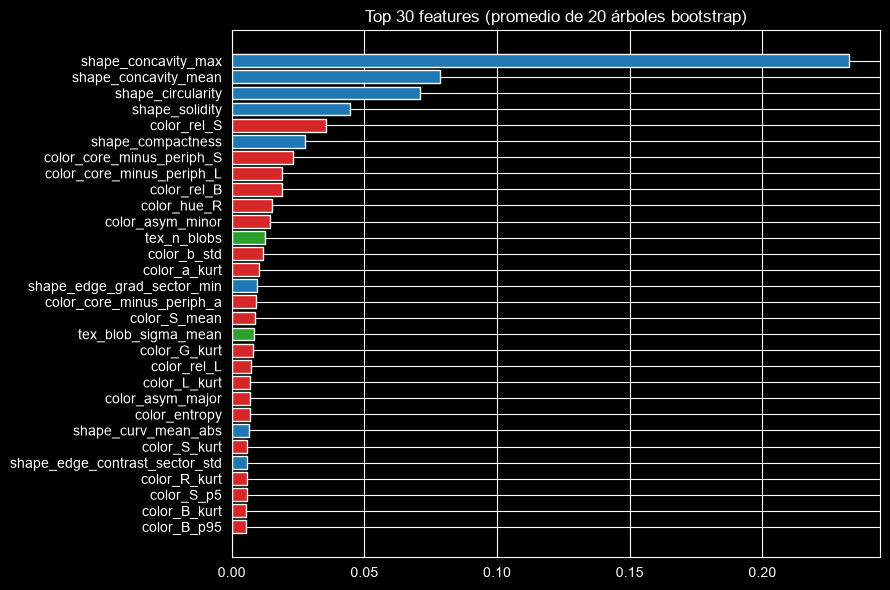

Familias en el top: {'color': 20, 'shape': 8, 'tex': 2}


In [5]:
class TreeTopK(BaseEstimator, TransformerMixin):
    """Se queda con las k features de mayor importancia media en árboles de decisión entrenados con bootstrap."""

    def __init__(self, k=20, n_rounds=20, max_depth=6, min_samples_leaf=10, random_state=0):
        self.k, self.n_rounds, self.max_depth = k, n_rounds, max_depth
        self.min_samples_leaf, self.random_state = min_samples_leaf, random_state

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        rng = np.random.RandomState(self.random_state)
        imp = np.zeros(X.shape[1])
        for _ in range(self.n_rounds):
            idx = rng.choice(len(y), len(y), replace=True)
            t = DecisionTreeClassifier(max_depth=self.max_depth, min_samples_leaf=self.min_samples_leaf,
                                       random_state=rng.randint(1_000_000_000)).fit(X[idx], y[idx])
            imp += t.feature_importances_
        self.importances_ = imp / self.n_rounds
        self.support_ = np.argsort(-self.importances_)[: self.k]
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.support_]


# lista de features elegidas con TODO train (solo para mostrarla; la CV lo hace dentro de cada fold)
selector = TreeTopK(k=K_FEATURES, random_state=SEED).fit(Xtr_i, ytr)
sel_imp = pd.Series(selector.importances_, index=FEATS).sort_values(ascending=False)
SELECTED = list(sel_imp.index[:K_FEATURES])
sel_imp.head(K_FEATURES).rename("importancia").to_csv(OUT_DIR / "selected_features.csv")

top = sel_imp.head(K_FEATURES)[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top.index, top.values, color=[FAM_COLOR[family(c)] for c in top.index])
plt.title(f"Top {K_FEATURES} features (promedio de 20 árboles bootstrap)")
plt.tight_layout(); plt.show()
print("Familias en el top:", pd.Series([family(c) for c in SELECTED]).value_counts().to_dict())

## 4. Baseline y otros modelos

- **Imputación** (mediana) → **selección top-K** (opcional) → **transformación cuantil a normal** (solo en modelos que
  la necesitan; las features tienen colas muy pesadas) → modelo.
- **Baseline**: regresión logística. `Dummy` es el suelo (AUC 0.5).
- Métricas en CV: AUC, balanced accuracy, F1 y **recall de `others`** (clase positiva = 1).
- Todos con hiperparámetros razonables por defecto, sin ajuste fino.

In [6]:
MODELS = {   # nombre: (estimador, ¿necesita escalado?)
    "Dummy": (DummyClassifier(strategy="prior"), False),
    "LogReg (baseline)": (LogisticRegression(C=0.5, max_iter=3000), True),
    "KNN": (KNeighborsClassifier(n_neighbors=15), True),
    "SVM-RBF": (SVC(C=1.0, gamma="scale"), True),
    "Decision Tree": (DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED), False),
    "Random Forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=1), False),
    "HistGradientBoosting": (HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_depth=4,
                                                           early_stopping=False, random_state=SEED), False),
}
SCORING = {"auc": "roc_auc", "bal_acc": "balanced_accuracy", "f1": "f1", "recall_others": "recall"}


def make_pipe(model, scale, k):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if k:
        steps.append(("sel", TreeTopK(k=k, random_state=SEED)))
    if scale:
        steps.append(("scale", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=SEED)))
    steps.append(("clf", model))
    return Pipeline(steps)


def run_cv(X, k, models=MODELS):
    out = {}
    for name, (est, scale) in models.items():
        r = cross_validate(make_pipe(est, scale, k), X, ytr, cv=skf, scoring=SCORING, n_jobs=N_JOBS)
        out[name] = {f"{m}": f"{r['test_' + m].mean():.3f} ± {r['test_' + m].std():.3f}" for m in SCORING}
        out[name]["_auc"] = r["test_auc"].mean()
    return pd.DataFrame(out).T.sort_values("_auc", ascending=False)


print(f"CV {CV_FOLDS} folds en train ({len(Xtr)} imágenes)\n")
res_all = run_cv(Xtr, k=None)
print(f"--- TODAS las features ({len(FEATS)}) ---")
print(res_all.drop(columns="_auc").to_string(), "\n")

res_top = run_cv(Xtr, k=K_FEATURES)
print(f"--- TOP-{K_FEATURES} (selección dentro de cada fold) ---")
print(res_top.drop(columns="_auc").to_string())

res_all.drop(columns="_auc").to_csv(OUT_DIR / "cv_all_features.csv")
res_top.drop(columns="_auc").to_csv(OUT_DIR / f"cv_top{K_FEATURES}.csv")

CV 5 folds en train (2000 imágenes)

--- TODAS las features (197) ---
                                auc        bal_acc             f1  recall_others
HistGradientBoosting  0.882 ± 0.012  0.811 ± 0.016  0.807 ± 0.014  0.804 ± 0.018
SVM-RBF               0.880 ± 0.004  0.805 ± 0.012  0.798 ± 0.011  0.785 ± 0.013
Random Forest         0.876 ± 0.009  0.799 ± 0.019  0.794 ± 0.017  0.783 ± 0.018
LogReg (baseline)     0.863 ± 0.008  0.777 ± 0.011  0.772 ± 0.011  0.767 ± 0.023
KNN                   0.852 ± 0.011  0.788 ± 0.014  0.781 ± 0.013  0.766 ± 0.023
Decision Tree         0.808 ± 0.013  0.751 ± 0.014  0.743 ± 0.021  0.738 ± 0.057
Dummy                 0.500 ± 0.000  0.500 ± 0.000  0.000 ± 0.000  0.000 ± 0.000 

--- TOP-30 (selección dentro de cada fold) ---
                                auc        bal_acc             f1  recall_others
SVM-RBF               0.873 ± 0.001  0.799 ± 0.017  0.792 ± 0.017  0.780 ± 0.017
HistGradientBoosting  0.872 ± 0.009  0.796 ± 0.011  0.792 ± 0.009  0.78

## 5. Ablación por familias
Mismo modelo (Random Forest, sin selección) con cada familia sola y combinadas. Sirve para ver cuánto aporta
cada una y si son complementarias.

In [7]:
fam_cols = {f: [c for c in FEATS if family(c) == f] for f in ["shape", "color", "tex"]}
subsets = {"solo forma": fam_cols["shape"], "solo color": fam_cols["color"], "solo textura": fam_cols["tex"],
           "forma + color": fam_cols["shape"] + fam_cols["color"], "color + textura": fam_cols["color"] + fam_cols["tex"],
           "todas": FEATS}
rf = {"Random Forest": MODELS["Random Forest"]}
abl = {name: run_cv(Xtr[cols], k=None, models=rf).iloc[0] for name, cols in subsets.items()}
abl = pd.DataFrame(abl).T
abl.insert(0, "n_features", [len(c) for c in subsets.values()])
print(abl.drop(columns="_auc").to_string())

                 n_features            auc        bal_acc             f1  recall_others
solo forma               76  0.827 ± 0.006  0.763 ± 0.016  0.752 ± 0.011  0.727 ± 0.009
solo color               83  0.866 ± 0.015  0.795 ± 0.014  0.791 ± 0.014  0.788 ± 0.024
solo textura             38  0.800 ± 0.011  0.733 ± 0.012  0.730 ± 0.020  0.736 ± 0.051
forma + color           159  0.872 ± 0.010  0.798 ± 0.018  0.792 ± 0.015  0.782 ± 0.012
color + textura         121  0.871 ± 0.012  0.790 ± 0.013  0.784 ± 0.011  0.777 ± 0.020
todas                   197  0.876 ± 0.009  0.799 ± 0.019  0.794 ± 0.017  0.783 ± 0.018


## 6. Evaluación final en val
Cada modelo se entrena con **todo train** (con la selección top-K dentro del pipeline) y se evalúa una sola vez en val.
Umbral de decisión por defecto (0.5). El IC del AUC se obtiene por bootstrap sobre las imágenes de val.

In [8]:
def get_score(pipe, X):
    return pipe.predict_proba(X)[:, 1] if hasattr(pipe, "predict_proba") else pipe.decision_function(X)


def boot_ci(y, s, n=1000, seed=0):
    rng, vals = np.random.RandomState(seed), []
    for _ in range(n):
        i = rng.choice(len(y), len(y), replace=True)
        if len(np.unique(y[i])) == 2:
            vals.append(roc_auc_score(y[i], s[i]))
    return np.percentile(vals, [2.5, 97.5])


fitted, rows, scores = {}, [], {}
for name, (est, scale) in MODELS.items():
    pipe = make_pipe(est, scale, K_FEATURES).fit(Xtr, ytr)
    s, pred = get_score(pipe, Xva), pipe.predict(Xva)
    lo, hi = boot_ci(yva, s)
    fitted[name], scores[name] = pipe, s
    rows.append({"modelo": name, "AUC": roc_auc_score(yva, s), "AUC IC95%": f"[{lo:.3f}, {hi:.3f}]",
                 "bal_acc": balanced_accuracy_score(yva, pred), "F1": f1_score(yva, pred),
                 "recall_others": recall_score(yva, pred), "precision_others": precision_score(yva, pred, zero_division=0)})
val_res = pd.DataFrame(rows).set_index("modelo").sort_values("AUC", ascending=False)
print(f"Val ({len(Xva)} imágenes), modelos con top-{K_FEATURES}:\n")
print(val_res.round(3).to_string())
val_res.round(4).to_csv(OUT_DIR / f"val_top{K_FEATURES}.csv")

Val (1000 imágenes), modelos con top-30:

                        AUC       AUC IC95%  bal_acc     F1  recall_others  precision_others
modelo                                                                                      
HistGradientBoosting  0.894  [0.875, 0.913]    0.818  0.817          0.827             0.807
SVM-RBF               0.889  [0.870, 0.910]    0.820  0.817          0.817             0.817
Random Forest         0.887  [0.868, 0.907]    0.813  0.809          0.807             0.811
KNN                   0.874  [0.853, 0.895]    0.803  0.804          0.821             0.787
LogReg (baseline)     0.873  [0.851, 0.894]    0.798  0.796          0.800             0.791
Decision Tree         0.844  [0.821, 0.866]    0.781  0.777          0.776             0.778
Dummy                 0.500  [0.500, 0.500]    0.500  0.000          0.000             0.000


Mejor modelo en CV: SVM-RBF


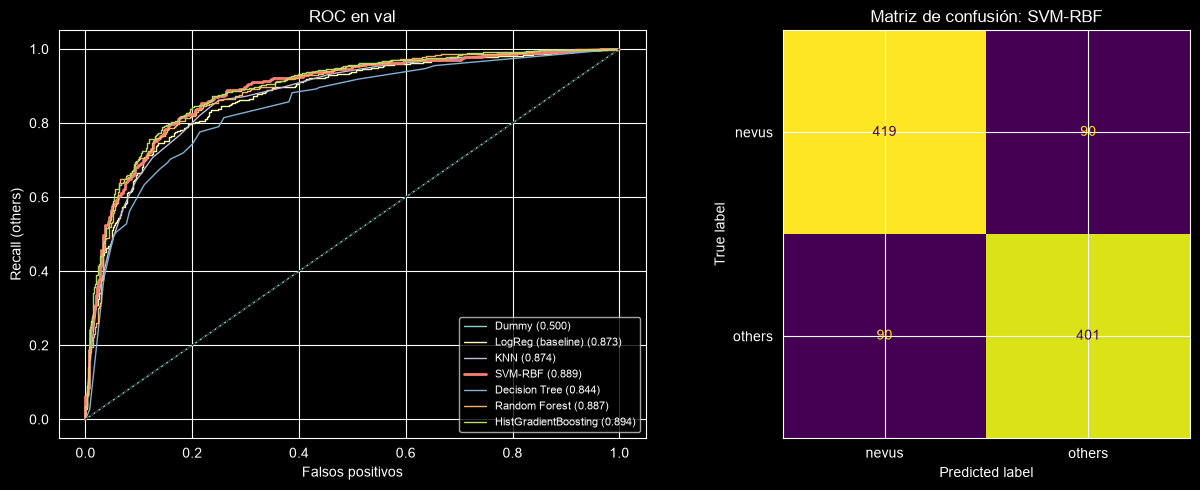

In [9]:
best = res_top.index[0]          # mejor modelo según AUC en CV (no según val)
print("Mejor modelo en CV:", best)

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(yva, s)
    axs[0].plot(fpr, tpr, lw=2 if name == best else 1, label=f"{name} ({roc_auc_score(yva, s):.3f})")
axs[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axs[0].set(xlabel="Falsos positivos", ylabel="Recall (others)", title="ROC en val"); axs[0].legend(fontsize=8)
ConfusionMatrixDisplay.from_predictions(yva, fitted[best].predict(Xva), display_labels=["nevus", "others"],
                                        ax=axs[1], colorbar=False)
axs[1].set_title(f"Matriz de confusión: {best}")
plt.tight_layout(); plt.show()

### ¿Qué features usa realmente el mejor modelo?
Importancia por permutación en val (cuánto cae el AUC al barajar cada feature). Sirve también para vigilar que
no dominen features raras (por ejemplo del color global) que podrían delatar la cámara y no la lesión.

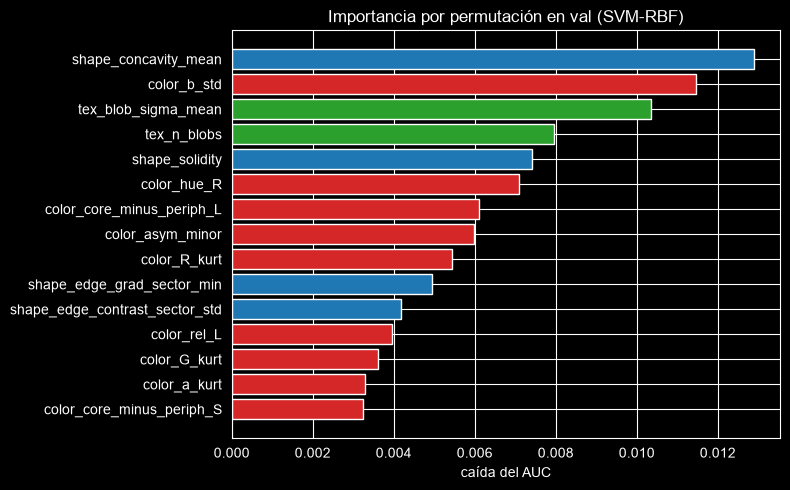

In [10]:
pi = permutation_importance(fitted[best], Xva, yva, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=N_JOBS)
pi = pd.Series(pi.importances_mean, index=FEATS).sort_values(ascending=False).head(15)[::-1]
plt.figure(figsize=(8, 5))
plt.barh(pi.index, pi.values, color=[FAM_COLOR[family(c)] for c in pi.index])
plt.title(f"Importancia por permutación en val ({best})")
plt.xlabel("caída del AUC"); plt.tight_layout(); plt.show()

In [11]:
ROOT = Path(r"C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG")
man = pd.read_csv(ROOT / "processed" / "manifest.csv").set_index("name")
cols = ["orig_h", "orig_w"]
m_tr, m_va = man.reindex(tr["name"])[cols], man.reindex(va["name"])[cols]
g = HistGradientBoostingClassifier(random_state=SEED).fit(m_tr, ytr)
print("AUC solo con el tamaño original:", roc_auc_score(yva, g.predict_proba(m_va)[:, 1]))

AUC solo con el tamaño original: 0.6844417591299581


In [12]:
pred = fitted[best].predict(Xva)
tmp = va[["subtype"]].assign(acierto=(pred == yva))
print(tmp.groupby("subtype")["acierto"].agg(["mean", "size"]).round(3))

          mean  size
subtype             
ack      0.935    46
bcc      0.874   135
bkl      0.811    95
def      1.000     5
mel      0.736   178
nev      0.823   509
scc      0.952    21
vac      0.636    11


In [13]:
sz = man.reindex(va["name"])[["orig_h", "orig_w"]].reset_index(drop=True)
va_sz = va[["name", "class"]].reset_index(drop=True).join(sz)
va_sz["res"] = va_sz["orig_w"].astype(str) + "x" + va_sz["orig_h"].astype(str)

print(pd.crosstab(va_sz["res"], va_sz["class"]).sort_values("nevus", ascending=False).head(10))

s, rows = scores[best], []
for res, g in va_sz.groupby("res"):
    y = yva[g.index]
    if len(g) >= 30 and 0 < y.mean() < 1:
        rows.append((res, len(g), round(y.mean(), 2), roc_auc_score(y, s[g.index])))
print(pd.DataFrame(rows, columns=["res", "n", "frac_others", "AUC"]).round(3))

class      nevus  others
res                     
600x450      250     119
1024x1024    176     334
1024x768      25       7
1024x680      23      23
1024x682      13       0
1024x679       3       1
1024x685       3       2
919x802        2       0
1022x767       2       0
767x576        2       1
         res    n  frac_others    AUC
0  1024x1024  510         0.65  0.883
1   1024x680   46         0.50  0.792
2   1024x768   32         0.22  0.914
3    600x450  369         0.32  0.890


In [14]:
# AUC solo melanoma vs nevus
m = va["subtype"].isin(["mel", "nev"]).values
print("AUC mel vs nev:", roc_auc_score(yva[m], scores[best][m]))

# sensibilidad de others a especificidad fija de nevus
fpr, tpr, _ = roc_curve(yva, scores[best])
for sp in [0.80, 0.90, 0.95]:
    print(f"especificidad {sp:.0%}: sensibilidad {tpr[np.searchsorted(fpr, 1 - sp, side='right') - 1]:.3f}")

AUC mel vs nev: 0.8452793536566521
especificidad 80%: sensibilidad 0.825
especificidad 90%: sensibilidad 0.686
especificidad 95%: sensibilidad 0.576
